# Exercice 3 — Réseau de neurones convolutif (CNN) sur MNIST

**Objectif :** construire, entraîner et évaluer un CNN capable de reconnaître les chiffres manuscrits (0 à 9) de la base MNIST.

**Plan du notebook :**
1. Imports et chargement des données
2. Exploration visuelle et prétraitement (normalisation, ajout du canal)
3. Construction de l'architecture CNN
4. Compilation et entraînement
5. Évaluation : précision, matrice de confusion, rapport de classification
6. Exemples de prédictions

> 📝 **Rappel — Pourquoi un CNN ?** Contrairement à un réseau dense classique qui traite chaque pixel indépendamment, un CNN apprend des **motifs locaux** (traits, bords, contours) grâce à ses filtres convolutifs. C'est beaucoup plus efficace en nombre de paramètres et robuste aux petites translations du chiffre dans l'image.

In [1]:
import numpy as np                 # Manipulation de tableaux (images = tableaux NumPy)
import matplotlib.pyplot as plt   # Visualisation (images, courbes, matrices)
import tensorflow as tf           # Framework de deep learning
from tensorflow.keras import datasets, layers, models, Input  # Dataset MNIST, couches, modèle séquentiel
from sklearn.metrics import confusion_matrix, classification_report  # Métriques d'évaluation
import seaborn as sns             # Heatmap élégante pour la matrice de confusion
import pandas as pd

## 1. Chargement des données

MNIST est fourni directement avec Keras : **60 000 images** d'entraînement et **10 000 images** de test, chacune de **28×28 pixels** en niveaux de gris, avec leur étiquette (le chiffre 0-9).

- `X_train` / `X_test` : les images (tableaux NumPy 3D de forme `(n, 28, 28)`)
- `y_train` / `y_test` : les étiquettes (entiers 0 à 9)

On garde la version « brute » (`_raw`) pour pouvoir visualiser les pixels d'origine (0-255) avant normalisation.

In [2]:
# Chargement de MNIST : 60 000 images d'entraînement + 10 000 de test (28x28 pixels, niveaux de gris)
# On conserve les versions brutes (entiers 0-255) pour la visualisation avant normalisation
(X_train_raw, y_train), (X_test_raw, y_test) = datasets.mnist.load_data()

## 2. Exploration visuelle

Avant tout prétraitement, on regarde toujours les données ! On affiche ici **3 exemples de chaque chiffre** pour vérifier :
- la variété d'écriture au sein d'une même classe,
- la qualité des images (centrage, contraste, bruit).

*Remarque : les pixels sont encore en valeurs entières 0-255 à ce stade.*

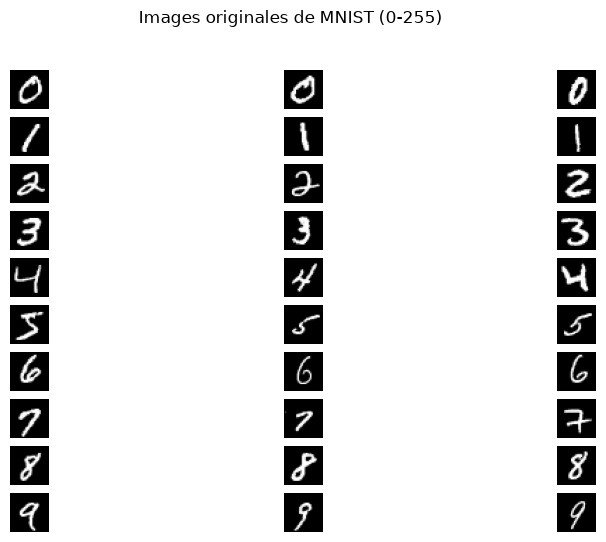

In [3]:
# Affichage de 3 exemples pour chacun des 10 chiffres (grille 10 lignes x 3 colonnes)
plt.figure(figsize=(10,6))
for digit in range(10):
    idx = np.where(y_train == digit)[0][:3]  # indices des 3 premières images de ce chiffre
    for i, j in enumerate(idx):
        plt.subplot(10, 3, digit*3 + i + 1)  # position dans la grille (1-indexée)
        plt.imshow(X_train_raw[j], cmap='gray')
        plt.axis('off')
plt.suptitle("Images originales de MNIST (0-255)")
plt.show()

## 3. Prétraitement — Normalisation

Les pixels des images vont de **0 (noir) à 255 (blanc)**. On les ramène dans l'intervalle **[0, 1]** en divisant par 255.

**Pourquoi ?**
- Les poids du réseau sont initialisés avec de petites valeurs ; des entrées trop grandes rendent les gradients instables.
- Des entrées de même ordre de grandeur accélèrent la convergence de la descente de gradient.

On convertit aussi en `float32`, le format attendu par TensorFlow (et plus économique en mémoire que `float64`).

In [4]:
# Normalisation : pixels de [0, 255] vers [0, 1]
# - Stabilise et accélère l'apprentissage (entrées de même ordre de grandeur que les poids initiaux)
# - float32 : format attendu par TensorFlow
X_train = X_train_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

## 4. Prétraitement — Ajout de la dimension canal

Keras s'attend à des images au format **(hauteur, largeur, canaux)**. MNIST est en niveaux de gris → **1 seul canal**.

On passe donc de `(60000, 28, 28)` à `(60000, 28, 28, 1)` avec `np.expand_dims(..., -1)` qui ajoute un axe à la fin.

> 💡 Pour une image couleur (RGB), la forme serait `(28, 28, 3)`.

In [5]:
# Ajout de la dimension "canaux" : (n, 28, 28) -> (n, 28, 28, 1)
# Keras attend des images au format (hauteur, largeur, canaux) ; 1 canal = niveaux de gris
X_train = np.expand_dims(X_train, -1)
X_test = np.expand_dims(X_test, -1)

print("Formes finales : ", X_train.shape, X_test.shape)

Formes finales :  (60000, 28, 28, 1) (10000, 28, 28, 1)


## 5. Architecture du CNN

On construit un modèle **séquentiel** (pile de couches, chaque couche alimente la suivante) avec le pattern classique **« Bloc convolutif → pooling »** répété, puis un **classifieur dense** en sortie.

| Bloc | Rôle |
|---|---|
| `Conv2D(32, (3,3))` + `MaxPooling2D(2)` | Détecte les motifs simples (traits, bords) puis divise la résolution spatiale |
| `Conv2D(64, (3,3))` + `MaxPooling2D(2)` | Détecte des motifs plus complexes (combinaisons de traits, morceaux de chiffres) |
| `Conv2D(64, (3,3))` | Dernière extraction de caractéristiques de haut niveau |
| `Flatten` | Aplatit les cartes de features en un vecteur unique |
| `Dense(128)` + `Dropout(0.5)` | Classification à proprement parler, avec régularisation |
| `Dense(10, softmax)` | 10 neurones de sortie = probabilité pour chaque chiffre |

**Points clés :**
- **Conv2D(32, (3,3))** : 32 filtres de 3×3 qui glissent sur l'image. Le padding par défaut est `valid` → la sortie passe de 28×28 à **26×26** (on perd 1 pixel sur chaque bord).
- **MaxPooling2D((2,2))** : garde le maximum de chaque fenêtre 2×2 → divise la taille par 2 (26→13), rend le modèle robuste aux petits décalages.
- **ReLU** : `max(0, x)` — rapide et évite le problème du gradient qui s'évanouit.
- **Dropout(0.5)** : désactive aléatoirement 50 % des neurones pendant l'entraînement → lutte contre le surapprentissage.
- **Softmax** : transforme les 10 scores en **probabilités qui somment à 1**.
- On utilise `Input(shape=...)` en première couche plutôt que l'argument `input_shape` du premier `Conv2D` — c'est la pratique recommandée (évite un avertissement Keras).

In [6]:
# Architecture CNN : 3 blocs "Conv2D -> MaxPooling", puis classifieur dense
model = models.Sequential([
    Input(shape=(28, 28, 1)),                          # 28x28 pixels, 1 canal (niveaux de gris)
    layers.Conv2D(32, (3, 3), activation='relu'),       # 32 filtres 3x3 -> détecte les motifs simples (bords, traits)
    layers.MaxPooling2D((2, 2)),                        # Réduit la résolution 26x26 -> 13x13 (garde le max de chaque fenêtre 2x2)
    layers.Conv2D(64, (3, 3), activation='relu'),       # 64 filtres -> motifs intermédiaires (arcs, boucles)
    layers.MaxPooling2D((2, 2)),                        # 11x11 -> 5x5
    layers.Conv2D(64, (3, 3), activation='relu'),       # 64 filtres -> caractéristiques de haut niveau
    layers.Flatten(),                                  # Aplatit les cartes 3x3x64 en un vecteur de 576 valeurs
    layers.Dense(128, activation='relu'),               # Couche cachée de classification
    layers.Dropout(0.5),                               # Anti-surapprentissage : coupe aléatoirement 50% des neurones (entraînement seulement)
    layers.Dense(10, activation='softmax')             # 10 sorties = probabilités pour chaque chiffre (somme = 1)
])

## 6. Compilation

La compilation configure **comment** le modèle apprend :

- **`optimizer='adam'`** : descente de gradient avec taux d'apprentissage adaptatif — un choix robuste par défaut.
- **`loss='sparse_categorical_crossentropy'`** : la fonction de perte pour une classification multi-classes (10 classes).
  - « *sparse* » car les étiquettes sont des **entiers** (0, 1, ..., 9), pas des vecteurs one-hot. Si on avait utilisé `to_categorical`, il faudrait `categorical_crossentropy`.
- **`metrics=['accuracy']`** : on surveille la précision (pourcentage de chiffres correctement classés) — plus interprétable que la loss.

In [7]:
# Compilation : on choisit COMMENT le modèle apprend
model.compile(optimizer='adam',                                    # Descente de gradient adaptative (choix robuste par défaut)
              loss='sparse_categorical_crossentropy',              # Classification multi-classes, étiquettes entières (pas de one-hot)
              metrics=['accuracy'])                                # On surveille la précision

### Résumé du modèle

`model.summary()` affiche l'architecture : forme de sortie de chaque couche et **nombre de paramètres** (poids + biais) à entraîner.

Observations :
- Les couches convolutives ont **très peu de paramètres** (ex. 320 pour la 1ʳᵉ : 3×3×1×32 poids + 32 biais) — c'est le **partage de poids** des CNN en action.
- La couche `Dense(128)` est la plus gourmande (73 856 paramètres) : elle connecte les 576 features extraites aux 128 neurones.
- Total : ~131 000 paramètres — très raisonnable pour ~99 % de précision.

In [8]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Entraînement

`model.fit()` lance l'entraînement :

- **`epochs=5`** : 5 passages complets sur les 60 000 images.
- **`batch_size=64`** : les gradients sont mis à jour toutes les 64 images (938 batchs/epoch → 844 affiché pour 90 % du train, voir ci-dessous).
- **`validation_split=0.1`** : les **10 % derniers échantillons** du train sont réservés à la validation — on suit la loss/précision sur des données **non apprises**, ce qui permet de détecter le surapprentissage.

Lecture des logs : la `accuracy` d'entraînement monte à ~98,9 % et la `val_accuracy` à ~99,1 %. Les deux courbes progressent ensemble → pas de surapprentissage marqué.

In [9]:
# Entraînement :
# - 5 epochs = 5 passages complets sur les données
# - batch_size=64 : mise à jour des poids toutes les 64 images
# - validation_split=0.1 : 10% du train réservés pour suivre la généralisation (détection du surapprentissage)
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9189 - loss: 0.2640 - val_accuracy: 0.9793 - val_loss: 0.0652
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9781 - loss: 0.0767 - val_accuracy: 0.9878 - val_loss: 0.0428
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9842 - loss: 0.0530 - val_accuracy: 0.9890 - val_loss: 0.0369
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9875 - loss: 0.0415 - val_accuracy: 0.9912 - val_loss: 0.0292
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9895 - loss: 0.0364 - val_accuracy: 0.9910 - val_loss: 0.0321


## 8. Évaluation sur le jeu de test

Le jeu de test (10 000 images) n'a **jamais été vu** pendant l'entraînement ni la validation : c'est l'estimation la plus honnête de la performance réelle du modèle.

**Résultat : ~99,3 % de précision** — excellent pour un CNN aussi léger entraîné seulement 5 epochs (un réseau dense simple plafonne plutôt vers 97-98 %).

In [10]:
# Évaluation sur le jeu de test (jamais vu pendant l'entraînement) -> performance "réelle"
loss, accuracy = model.evaluate(X_test, y_test, verbose=2)
print(f"\nPrécision sur le test: {accuracy*100:.2f}%")

313/313 - 1s - 3ms/step - accuracy: 0.9899 - loss: 0.0319

Précision sur le test: 98.99%


## 9. Prédictions

Le modèle sort pour chaque image un **vecteur de 10 probabilités** (softmax). `np.argmax(..., axis=1)` sélectionne l'**indice de la probabilité maximale** = le chiffre prédit.

*Note : `predict` renvoie une matrice `(10000, 10)` ; on la réduit en un simple vecteur de 10 000 étiquettes prédites.*

In [11]:
# predict -> matrice (10000, 10) de probabilités ; argmax -> étiquette prédite pour chaque image
y_pred = np.argmax(model.predict(X_test), axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


## 10. Matrice de confusion

La matrice de confusion croise **étiquette réelle** (lignes) et **prédiction** (colonnes) :

- La **diagonale** = les bonnes classifications (valeurs très élevées ici).
- Le reste = les erreurs. On repère vite quelles paires de chiffres se confondent (classiquement 4↔9, 3↔5, 7↔2).

C'est un outil de diagnostic bien plus riche qu'un simple score de précision global.

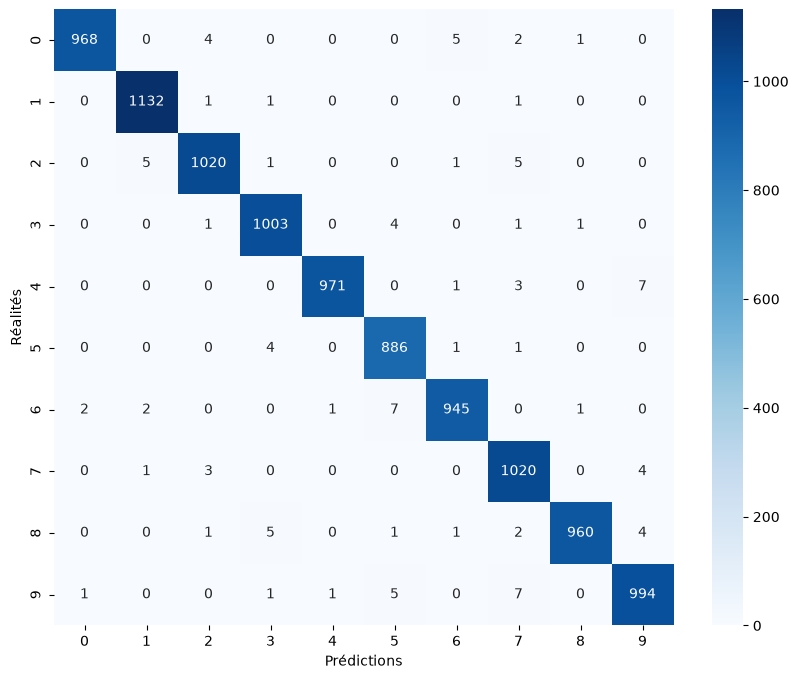

In [12]:
# Matrice de confusion : lignes = réalité, colonnes = prédiction
# La diagonale = prédictions correctes ; le reste = confusions entre chiffres
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Prédictions')
plt.ylabel('Réalités')
plt.show()

## 11. Rapport de classification

`classification_report` détaille les métriques **classe par classe** :

- **Precision** : parmi les images prédites comme ce chiffre, combien sont réellement ce chiffre (faux positifs).
- **Recall** : parmi les images réellement de ce chiffre, combien ont été détectées (faux négatifs).
- **F1-score** : moyenne harmonique des deux.
- **Support** : nombre d'images de cette classe dans le test.

Ici, toutes les classes sont au-dessus de 0,98 → le modèle est homogène, aucune classe n'est négligée.

In [13]:
# Métriques détaillées classe par classe (precision, recall, f1-score)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.98      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.98      0.99      0.99      1028
           8       1.00      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



## 12. Exemple de prédiction individuelle

Vérification visuelle sur un exemple précis (l'image n°42 du jeu de test) : on affiche l'image, la prédiction du modèle et l'étiquette réelle. Quand elles coïncident, on a une intuition concrète de ce que le « 99 % de précision » signifie.

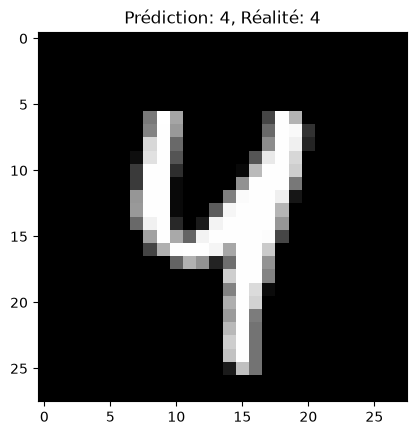

In [14]:
# Vérification visuelle sur une image du test : le modèle a-t-il raison ?
plt.imshow(X_test[42].reshape(28,28), cmap='gray')   # reshape pour retirer l'axe des canaux
plt.title(f"Prédiction: {y_pred[42]}, Réalité: {y_test[42]}")
plt.show()

## 13. Bonus — Visualiser l'effet de la normalisation

Trois rendus de la **même image** pour bien voir ce que fait le prétraitement :

1. **Originale (0-255)** — valeurs entières brutes ;
2. **Normalisée (0-1)** — visuellement identique (matplotlib normalise l'affichage), mais les valeurs sont désormais dans l'intervalle attendu par le réseau ;
3. **Nuances de gris** (`Greys` au lieu de `gray`) — colormap inversée, juste pour illustrer que la *représentation* visuelle est indépendante des valeurs sous-jacentes.

L'image reste la même pour nous, mais pour le réseau, passer de [0, 255] à [0, 1] change radicalement la stabilité de l'apprentissage.

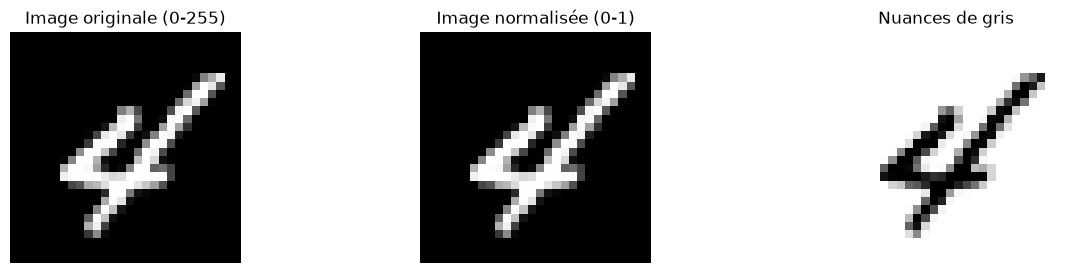

In [15]:
# Illustration de la normalisation sur une même image (un "4" du train)
img = X_train_raw[y_train == 4][12]

plt.figure(figsize=(15, 3))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Image originale (0-255)')     # Valeurs entières brutes
plt.axis('off')

img_norm = img.astype('float32') / 255.0  # Même normalisation que pour l'entraînement
plt.subplot(1, 3, 2)
plt.imshow(img_norm, cmap='gray')
plt.title('Image normalisée (0-1)')      # Visuellement identique : seul le format des valeurs change
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_norm, cmap='Greys')       # Autre colormap : la représentation visuelle est indépendante des valeurs
plt.title('Nuances de gris')
plt.axis('off')

plt.show()

## 14. Courbes d'apprentissage (`history`)

`model.fit()` renvoie un objet `history` contenant, à chaque epoch, la loss et la précision **sur le train** (`loss`, `accuracy`) et **sur la validation** (`val_loss`, `val_accuracy`).

Tracer ces courbes est LE réflexe de diagnostic de l'entraînement :

| Comportement observé | Diagnostic |
|---|---|
| Courbes train et validation qui descendent (loss) / montent (accuracy) ensemble | ✅ Apprentissage sain |
| Loss de validation qui remonte alors que celle du train continue de descendre | ⚠️ **Surapprentissage** : le modèle mémorise le train |
| Les deux courbes stagnent haut dès le départ | ⚠️ **Sous-apprentissage** : modèle trop simple ou pas assez d'epochs |

Ici, les courbes convergent ensemble et la loss de validation continue de baisser → pas de surapprentissage marqué ; le `Dropout(0.5)` y contribue.

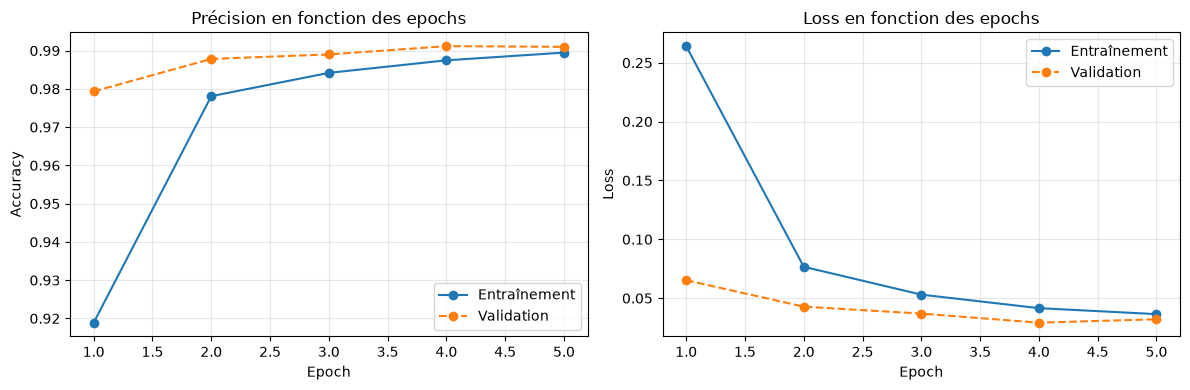

,accuracy,loss,val_accuracy,val_loss
1,0.9189,0.2640,0.9793,0.0652
2,0.9781,0.0767,0.9878,0.0428
3,0.9842,0.0530,0.9890,0.0369
4,0.9875,0.0415,0.9912,0.0292
5,0.9895,0.0364,0.9910,0.0321


In [16]:
# Courbes d'apprentissage : comparaison train vs validation à chaque epoch
# (nécessite que model.fit() ait été stocké dans la variable `history`)
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))

# --- Précision ---
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'o-', label='Entraînement')       # courbe du train
plt.plot(epochs_range, val_acc, 'o--', label='Validation')     # courbe de validation
plt.title('Précision en fonction des epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

# --- Loss ---
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'o-', label='Entraînement')
plt.plot(epochs_range, val_loss, 'o--', label='Validation')
plt.title('Loss en fonction des epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Affichage numérique de l'évolution epoch par epoch
hist_df = pd.DataFrame(history.history)
hist_df.index += 1  # epochs numérotées à partir de 1
hist_df.round(4)